Importing libraries:

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

Load Dataset:

In [2]:
dataset=pd.read_csv("Mall_Customers.csv")

Features Split:

In [3]:
X=dataset.iloc[:,[3,4]].values

Standard Scaler:

In [4]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
X_scaled=sc.fit_transform(X)

Train a Model:

In [5]:
from sklearn.cluster import AffinityPropagation
cluster=AffinityPropagation(damping=0.5, max_iter=150, convergence_iter=15, preference=-30, affinity='euclidean', random_state=42)
labels=cluster.fit_predict(X_scaled)

Display the Cluster lables:

In [6]:
labels

array([0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 2, 1, 2, 2,
       0, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 4, 3, 2, 3, 4, 3, 4, 3,
       2, 3, 4, 3, 4, 3, 4, 3, 4, 3, 2, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3,
       4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3,
       4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3,
       4, 3])

Create a DataFrame to Existing Dataset:

In [7]:
Clustered_dataset=pd.DataFrame(dataset)

Add Labels to the Existing Dataset:

In [8]:
Clustered_dataset["Clustered_Group"]=labels
Clustered_dataset

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Clustered_Group
0,1,Male,19,15,39,0
1,2,Male,21,15,81,1
2,3,Female,20,16,6,0
3,4,Female,23,16,77,1
4,5,Female,31,17,40,0
...,...,...,...,...,...,...
195,196,Female,35,120,79,3
196,197,Female,45,126,28,4
197,198,Male,32,126,74,3
198,199,Male,32,137,18,4


Plot the Cluster's Graph:

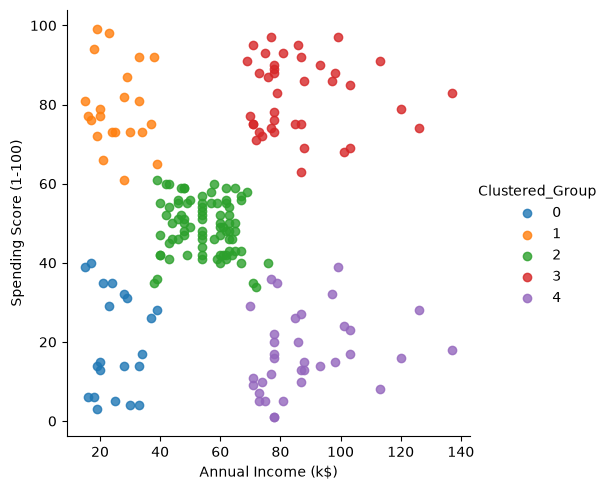

In [9]:
import seaborn as sns
facet=sns.lmplot(data=Clustered_dataset,x=Clustered_dataset.columns[3],y=Clustered_dataset.columns[4],hue=Clustered_dataset.columns[5],fit_reg=False,legend=True)
facet

Evaluation Metrics:

In [10]:
from sklearn.metrics import silhouette_score
score=silhouette_score(X_scaled,labels)
print("The Model Segregated score(-1 to +1) :",score)

The Model Segregated score(-1 to +1) : 0.5554176238283565


Display the Required datas:

In [11]:
print("Number of Clusters:", len(set(labels)))

print("Exemplar Indices:",cluster.cluster_centers_indices_)

print("Number of Iterations:", cluster.n_iter_)

Number of Clusters: 5
Exemplar Indices: [ 24  25  77 175 176]
Number of Iterations: 57


Average Annual Income and Spending Score by Cluster for Final Understanding:

In [12]:
cluster_profile=Clustered_dataset.groupby('Clustered_Group')[
    ['Annual Income (k$)','Spending Score (1-100)']
    ].mean()
print(cluster_profile)

                 Annual Income (k$)  Spending Score (1-100)
Clustered_Group                                            
0                         25.142857               19.523810
1                         25.727273               79.363636
2                         54.891566               49.180723
3                         86.538462               82.128205
4                         88.200000               17.114286


Count the Dataset Lables Based on Uniques:

In [13]:
print(Clustered_dataset['Clustered_Group'].value_counts())

Clustered_Group
2    83
3    39
4    35
1    22
0    21
Name: count, dtype: int64


Save the Scaling,Model & Cluster_Dataset:

In [14]:
import pickle
sc_filename='StandardScalered.sav'
model_filename='Finalized_model.sav'
dataset_filename='deployment_dataset.sav'
pickle.dump(sc,open(sc_filename,'wb'))
pickle.dump(cluster,open(model_filename,'wb'))
pickle.dump(cluster_profile,open(dataset_filename,'wb'))